# Basics of stitching the .hdf5 
Note: this is just a quick example!

In [2]:
from pathlib import Path
import numpy as np
from spectral import envi
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from numpy.typing import NDArray
import h5py
from stitching_functions import convert_to_reflectance, walk_h5, plot_stripes

# Path to raw data.
filename: str = '005.hdf5'
camera: str = 'FX17'
path: str = f'/n/archive/labs/hsi-data/johanna/WHISPERS26/data/{camera}/raw/{filename}' #TODO: CHANGE THIS LATER!


# Loading the raw files
f: h5py.File = h5py.File(path, "r")
print("Opened:", filename)

Opened: 005.hdf5


## Plotting strips and aligning white reference.

📄 Dataset: /black_ref_0  shape=(40, 640, 224)  dtype=uint16
📄 Dataset: /black_ref_1  shape=(40, 640, 224)  dtype=uint16
📄 Dataset: /black_ref_2  shape=(40, 640, 224)  dtype=uint16
📄 Dataset: /black_ref_3  shape=(40, 640, 224)  dtype=uint16
📄 Dataset: /black_ref_4  shape=(40, 640, 224)  dtype=uint16
📄 Dataset: /img_data_0  shape=(2235, 640, 224)  dtype=uint16
📄 Dataset: /img_data_1  shape=(2235, 640, 224)  dtype=uint16
📄 Dataset: /img_data_2  shape=(2235, 640, 224)  dtype=uint16
📄 Dataset: /img_data_3  shape=(1941, 640, 224)  dtype=uint16
📄 Dataset: /img_data_4  shape=(2235, 640, 224)  dtype=uint16


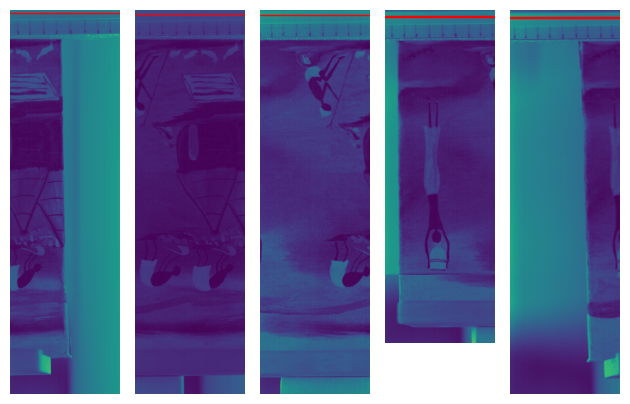

In [2]:
# Plots info on the strips
for k in f.keys():
    walk_h5(f"/{k}", f[k])


# white ref strip location
x, y = 0, 15     # rectangle top-left corner position
h = 3      # height of white strip
white_step = 7  # by how much white needs to be adjusted (moved up) as the going through the strips


# Plotting the image strips and locating white refs
key_list = list(f.keys())
num_of_scans = len(f.keys()) // 2
_ = plot_stripes(path, alignment='N', x_white=x, y_white=y, h_white=h, vstep=white_step) # Plotting band b of all image strips and locating the white refs
plt.show()

## Reflectance calculations for strips

In [3]:
from stitching_functions import make_strip_canvas, load_corrected_images


# Calculating reflectances
images = load_corrected_images(f, white_y=y, white_h=h, indices=range(num_of_scans) , flip_vertical=True, vstep=white_step)

Current y is:  15


Current y is:  22
Current y is:  29
Current y is:  36
Current y is:  43


## NaN padding
- If all the strips above look full-sized, this part can be skipped.
(This is a quick and messy version)

-------------- Before NaN padding --------------
(2235, 640, 224)
(2235, 640, 224)
(2235, 640, 224)
(1941, 640, 224)
(2235, 640, 224)
(744, 640, 224)
-------------- After padding --------------
(2235, 640, 224)
(2235, 640, 224)
(2235, 640, 224)
(2235, 640, 224)
(2235, 640, 224)


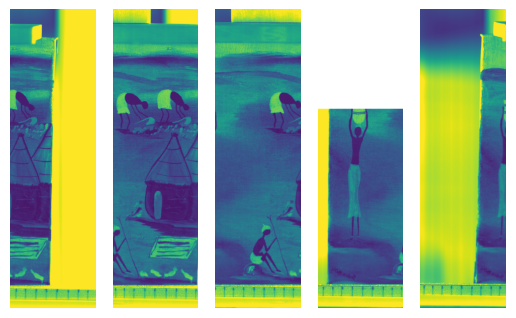

In [12]:

print('-------------- Before NaN padding --------------')
for idx, image in enumerate(images):
    # images[idx] = image[-2320:, :, :] # Cropping, so most the same size
    print(images[idx].shape)

## ------------- nan padding -------------------

full_height = 2235  # height of a complete strip, change manually
pad_until =  450  # starting point of padding
og_width = 640
og_wls = 224
padid = 3  # the inndex of the strip that needs padding
height_pad = images[padid].shape[0] # height of the strip that needs padding
pad_this_img = images[padid] 


# # Padding out the other strip that is a bit undersized. 
# # Modify manually as needed.
nan_pad = np.full((full_height-(height_pad-pad_until), og_width, og_wls), np.nan)
print(nan_pad.shape)
img_padded = np.concatenate([nan_pad, pad_this_img[pad_until:]])
images[padid] = img_padded

# Cropping the strips to match in size
# images

band = 100
fig, axes = plt.subplots(1, len(images), dpi=100)
print('-------------- After padding --------------')

for ax, cube in zip(axes, images):
    print(cube.shape)
    ax.imshow(cube[:, :, band], vmin=0, vmax=1)
    ax.set_anchor('S')  # align all strips to bottom
    ax.axis('off')

# plt.tight_layout()
plt.show()


## Stitching a canvas

In [8]:
cube.shape[1]

640

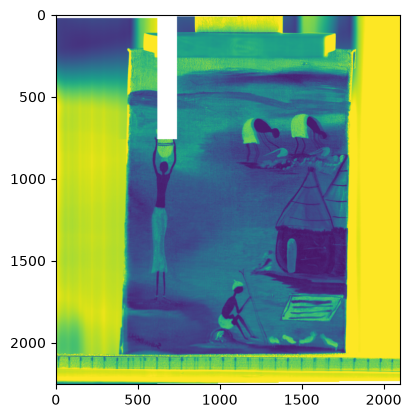

In [15]:
from stitching_functions import make_strip_canvas_nanfriendly

offset = 250  # overlap
# offset = 465  # overlap
width  = cube.shape[1] - 20

# 2) Feathered blend across overlaps
canvas_blend = make_strip_canvas_nanfriendly(
    images, width=width, offset=offset,
    crop_start=10, vstep=5, top_extra=0, extra_last=0,
    reverse_for_layout=True,  # true if image strips "mirror images" from what they should be, false if they OK
    blend_edges=True,         # set to true when image ready to be saved!!
    blend_threshold=None,      # pure linear feather
)

plt.imshow(canvas_blend[:,:, 100], vmin=0, vmax=1)
plt.show()

## Cropping

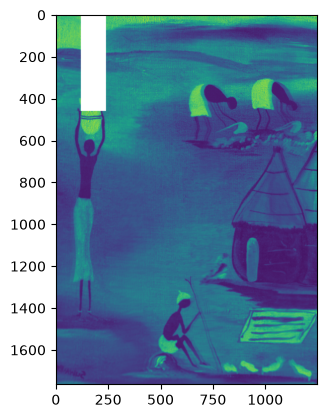

In [31]:
# Cropping
cropped_canvas = canvas_blend[300:-190, 500:1750, :]
# cropped_canvas = canvas_blend[1400:1650, 3100:3500, :]
plt.imshow(cropped_canvas[:, :, 100], vmin=0, vmax=1)

## Final touches 
- Flipping the image, if needed, and saving it.
- If the image appears very distorted, see ``resizing.ipyb``

In [1]:
# Flipping image if needed
cropped_canvas = np.flip(cropped_canvas, axis=1)
plt.imshow(cropped_canvas[..., 100])
plt.show()

NameError: name 'np' is not defined

In [ ]:
# # Saving the results
# save_path = f'../data/{camera}/reflectance'
# name = 'example'
# np.save(f'{save_path}/{name}.npy', cropped_canvas)
